# 05 Final evaluation and analysis

**Owners:** both. **Runs in:** about 2 minutes (cached results); `scripts/evaluate_test.py` re-runs the locked test evaluation.

The test split (6,149 images) is clustered with the frozen settings; scaling and PCA were fitted on train+val. Only now are the species labels used, and only for scoring:

- **Rand index (RI):** share of image pairs on which the grouping and the species agree (same/same or different/different).
- **Adjusted Rand index (ARI):** RI corrected so that random grouping scores 0.
- **Normalised mutual information (NMI):** how much knowing the group tells you about the species (0 to 1).
- **Silhouette:** label-free, as in notebook 04.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from p22 import config, data
pd.set_option("display.precision", 3)

In [2]:
summary = pd.read_csv(config.RESULTS_DIR / "final_metrics.csv")
cols = ["representation", "method", "k", "nmi_mean", "ari_mean", "rand_index_mean", "silhouette_mean"]

## 1. The frozen choices

In [3]:
summary[summary.selected][cols]

,representation,method,k,nmi_mean,ari_mean,rand_index_mean,silhouette_mean
5,hand_hsv_lbp,kmeans,10,0.223,0.047,0.885,0.045
20,hand_rgb_lbp,kmeans,10,0.191,0.035,0.878,0.046
35,mean_colour,kmeans,10,0.200,0.028,0.871,0.266
50,resnet50,average_cosine,10,0.095,0.003,0.116,0.088


## 2. Per-method label-free choices (D12)

In [4]:
pd.read_csv(config.RESULTS_DIR / "per_method_metrics.csv")[
    ["representation", "method", "k", "nmi_mean", "ari_mean", "silhouette_mean", "largest_cluster_share_mean"]]

,representation,method,k,nmi_mean,ari_mean,silhouette_mean,largest_cluster_share_mean
0,hand_hsv_lbp,average_cosine,10,0.183,0.029,-0.015,0.297
1,hand_hsv_lbp,kmeans,10,0.223,0.047,0.045,0.156
2,hand_hsv_lbp,ward,200,0.462,0.109,0.019,0.021
3,hand_rgb_lbp,average_cosine,10,0.164,0.023,-0.010,0.306
4,hand_rgb_lbp,kmeans,10,0.191,0.035,0.046,0.165
5,hand_rgb_lbp,ward,190,0.434,0.088,0.009,0.020
6,mean_colour,average_cosine,20,0.235,0.037,0.087,0.110
7,mean_colour,kmeans,10,0.200,0.028,0.266,0.207
8,mean_colour,ward,200,0.363,0.034,0.198,0.020
9,resnet50,average_cosine,10,0.095,0.003,0.088,0.947


## 3. Representation x method x number of groups
k = 102 is the true species count; it is outside knowledge, so it is a reference point only.

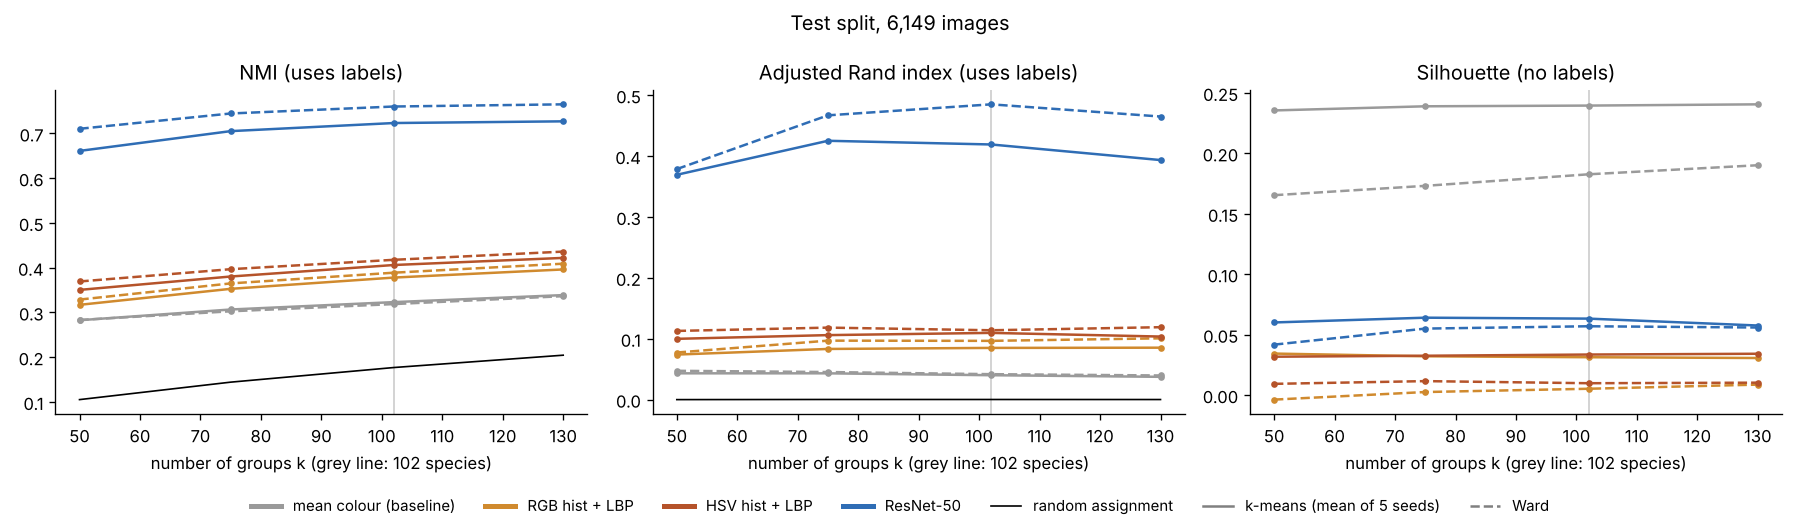

k                                50     75     102    130
representation method                                    
hand_hsv_lbp   average_cosine  0.318  0.355  0.381  0.410
               kmeans          0.350  0.380  0.406  0.422
               ward            0.369  0.397  0.417  0.436
hand_rgb_lbp   average_cosine  0.289  0.324  0.354  0.370
               kmeans          0.317  0.353  0.378  0.396
               ward            0.329  0.365  0.389  0.409
mean_colour    average_cosine  0.276  0.293  0.310  0.320
               kmeans          0.282  0.306  0.323  0.339
               ward            0.283  0.302  0.319  0.336
random         random          0.105  0.144  0.177  0.204
resnet50       average_cosine  0.332  0.442  0.503  0.524
               kmeans          0.661  0.705  0.723  0.727
               ward            0.710  0.744  0.760  0.765

In [5]:
display(Image(config.FIGURES_DIR / "metrics_vs_k.png"))
summary[summary.k.isin(config.K_REPORT)].pivot_table(index=["representation", "method"], columns="k", values="nmi_mean")

## 4. Why the Rand index is misleading here
With ~100 groups and ~100 species, almost every pair of images is "different species, different group", so even random assignment scores near 1.

In [6]:
summary[(summary.k == 102) & summary.method.isin(["random", "kmeans"])][["representation", "rand_index_mean", "ari_mean"]]

,representation,rand_index_mean,ari_mean
8,hand_hsv_lbp,0.977,1.095e-01
23,hand_rgb_lbp,0.976,8.479e-02
38,mean_colour,0.974,3.992e-02
48,random,0.976,5.188e-05
58,resnet50,0.985,4.189e-01


## 5. Do groups follow colour or species?
For each representation, k-means at k = 102. We compare its NMI with the species and with groups made from mean colour alone (k-means on the 3 mean RGB values, same k).

In [7]:
pd.read_csv(config.RESULTS_DIR / "colour_vs_species.csv")

,representation,k,nmi_with_species,nmi_with_colour_groups,median_cluster_purity
0,mean_colour,102,0.324,0.794,0.181
1,hand_rgb_lbp,102,0.379,0.368,0.209
2,hand_hsv_lbp,102,0.407,0.369,0.241
3,resnet50,102,0.723,0.329,0.803


## 6. Failure cases
Purest and least pure clusters (k-means, k = 102). For the hand-crafted features, one impure cluster collects flowers photographed on **black backgrounds** across many species: the background, not the flower, drives the colour histogram.

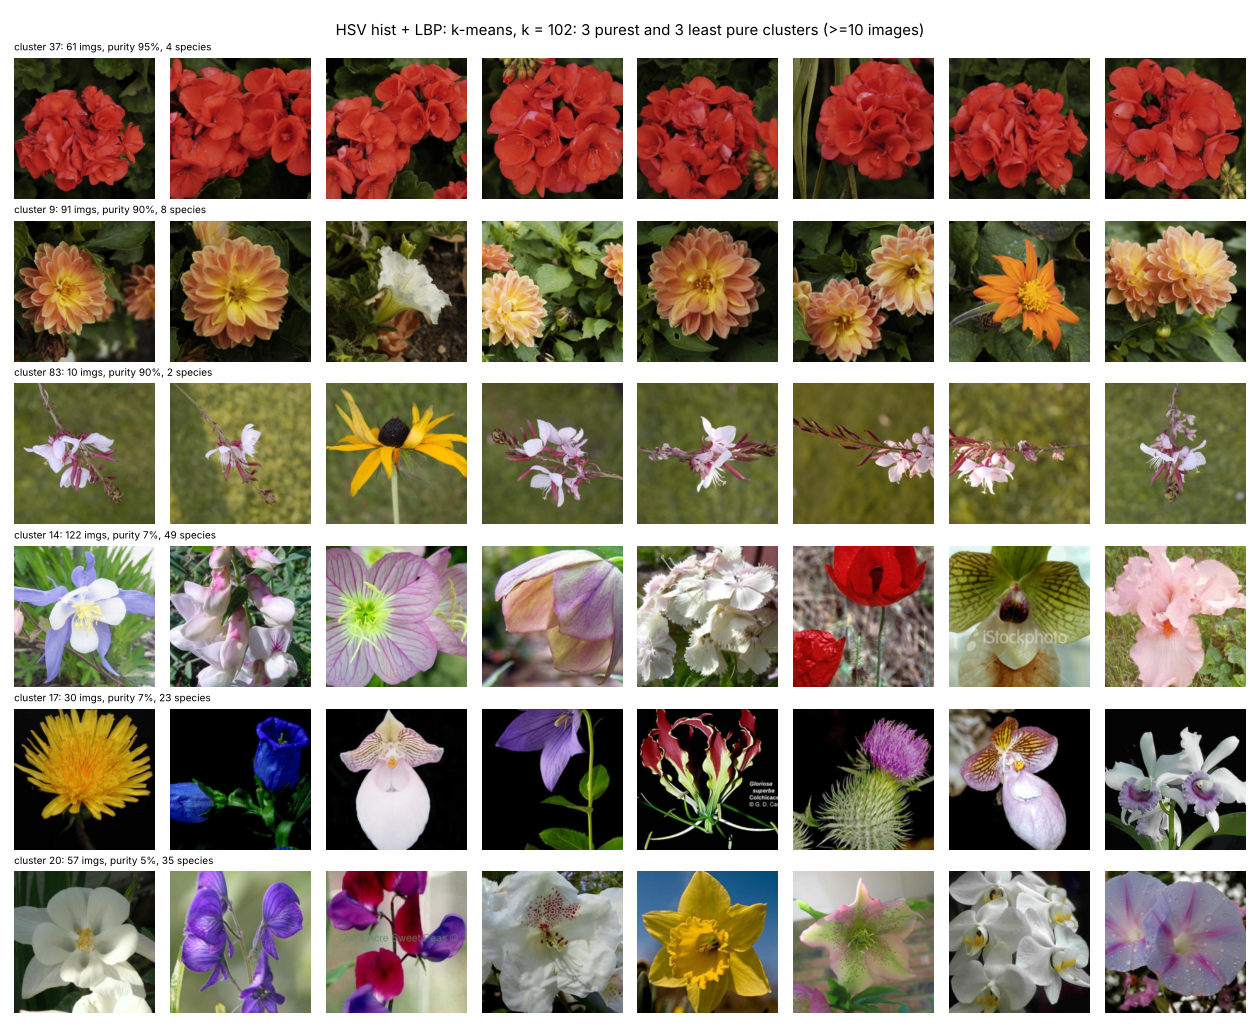

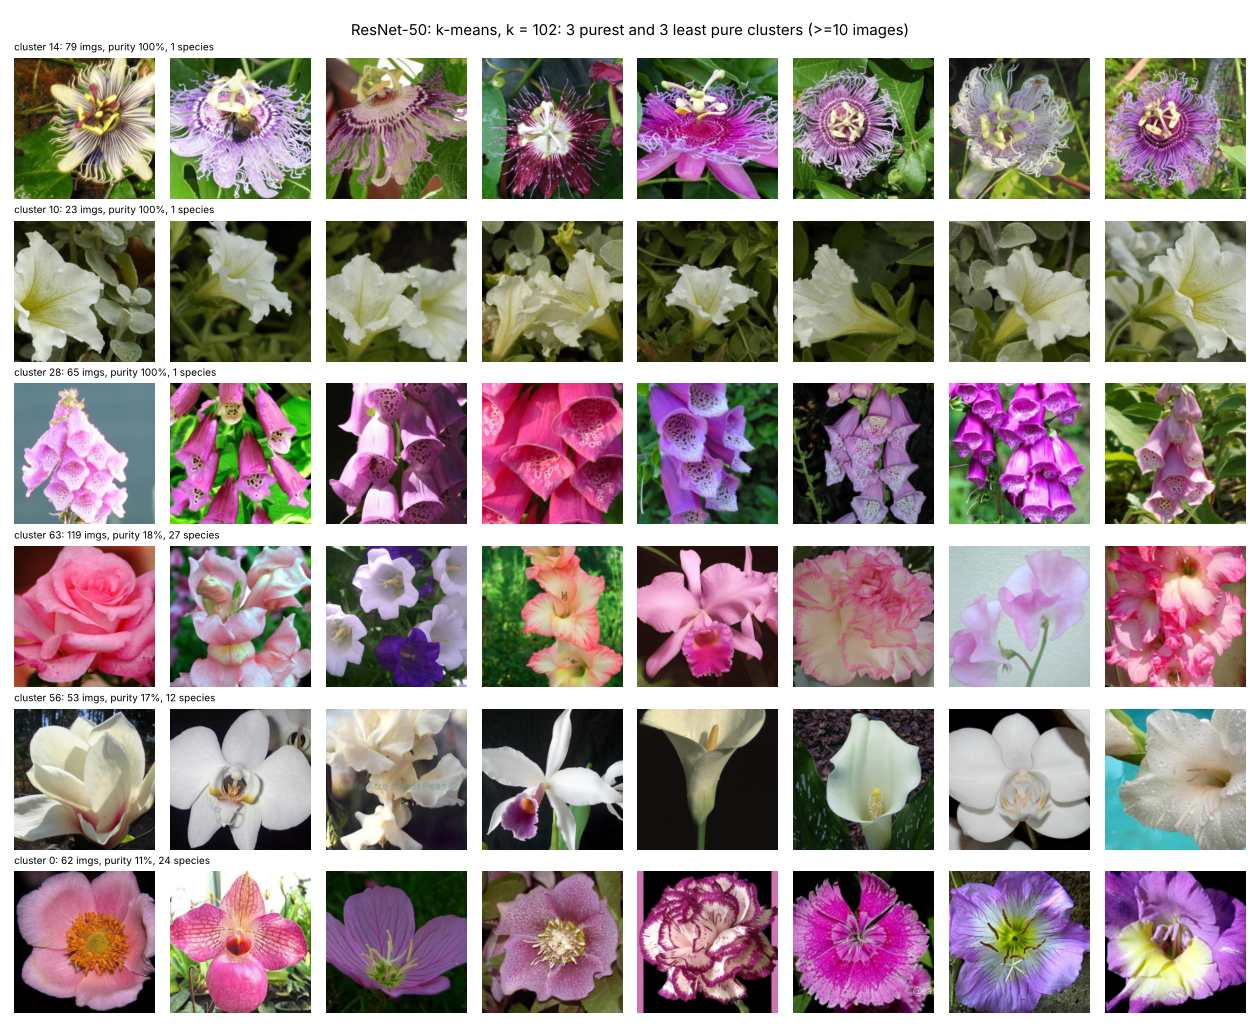

In [8]:
for rep in ["hand_hsv_lbp", "resnet50"]:
    display(Image(config.FIGURES_DIR / f"cluster_grid_{rep}.png"))

## 7. Species that split across many clusters (ResNet-50, k = 102)

In [9]:
pd.read_csv(config.RESULTS_DIR / "species_spread_resnet50.csv").head(10)

,species,images,clusters_used,share_in_main_cluster
0,51,238,23,0.164
1,96,71,24,0.169
2,84,66,22,0.182
3,101,38,14,0.184
4,31,32,16,0.188
5,4,36,16,0.194
6,45,20,11,0.200
7,3,20,11,0.200
8,72,76,15,0.211
9,97,46,14,0.217


## Conclusions
1. **Representation matters most.** ResNet-50 features roughly double NMI and quadruple ARI compared with colour + texture, at every k and with both main methods.
2. **Method matters less.** Ward is slightly ahead of k-means; average-cosine linkage is worst and can collapse into one giant group.
3. **Silhouette is a weak guide to species.** It favours few groups and ranks the colour baseline highest, the opposite of the label-based scores.
4. **Hand-crafted features group by colour and background**, not by species.